<a href="https://colab.research.google.com/github/elianpuuig/AM2/blob/main/TP2_ML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Practico Numero dos

# Aprendizaje automatico



---


*En este trabajo voy a recrear dos tutoriales oficiales de pytorch*

1.   Clasificacion de Audio
2.   Pipeline de reconocimiento de voz



In [ ]:
#aca es la importacion de paquetes comunes para torch audio que muestra el tutorial
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset
import torchaudio
import pandas as pd
import numpy as np

Voy a comprobar si existe una GPU en la maquina con CUDA disponible, esto ayuda a reducir el tiempo de ejecucion de entrenamiento y prueba

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


# Importacion del dataset

el dataset que voy usar para entrenar a la red neuronal es el de UrbanSound8k. es el que se usa en el tutorial de pythorch  

lo descargue desde: https://urbansounddataset.weebly.com/ traje el dataset

In [ ]:
# !pip install -q soundata

In [ ]:
# import soundata

# dataset = soundata.initialize('urbansound8k')
# dataset.download()
# dataset.validate()

# print(dataset.data_home)

5.61GB [37:06, 2.71MB/s]                            
1.15MB [00:02, 430kB/s]                            
100%|██████████| 8732/8732 [00:35<00:00, 243.13it/s]

/root/sound_datasets/urbansound8k


estos son los sonidos que contiene el dataset de audio


1. son aire acondicionado
2. bocina de coche
3. niños jugando
4. ladrido de perro
5. perforación
6. motor en ralentí
7. disparo
8. martillo neumático
9. sirena
10. música callejera



In [ ]:
#leyendo el dataset
csvData = pd.read_csv("/root/sound_datasets/urbansound8k/metadata/UrbanSound8K.csv")
print(csvData.iloc[0, :])

slice_file_name    100032-3-0-0.wav
fsID                         100032
start                           0.0
end                        0.317551
salience                          1
fold                              5
classID                           3
class                      dog_bark
Name: 0, dtype: object


# Reproduciendo algunos audios

In [ ]:
import IPython.display as ipd
audio_path = "/root/sound_datasets/urbansound8k/audio/"
ipd.Audio(f'{audio_path}fold1/108041-9-0-5.wav')

In [ ]:
ipd.Audio(f'{audio_path}fold5/100852-0-0-19.wav')

Una vez que vimos el fomrato de entrada del archivo csv voy a contruir el dataset

Para eso creo una clase envoltorio(wrapper) para el dataset usando torch.utils.data.Dataset
esto carga los archivos y los formatea

---


como el dataset tiene 10 capetas de audio voy a usar 9 para entrenar la red y 1 para prueba.


---


la clase envoltorio va a almacenar los archivos y carpetas para luego cargarlos y formatearlos en la funcion getitem donde usamos torchaudio.load() para pasarlos de .wav a tensores, esto devuelve una tupla con el tensor y su frecuencia de muestreo del archivo de audio

---

el dataset usa dos caneles de audio por lo que voy a usar torchaudio.transforms.DownmixMono() para convertir los datos de AUDIO a CANAL

para hacer el submuestreo tomamos solo la quinta parte de cada tensor de audio original, pero a lo que no son tan largos estos tensores tenemos que rellenarlos con ceros. la longitud minima que no necestia relleno es 160,000 muestras

In [ ]:
class UrbanSoundDataset(Dataset):
    # envoltorio para el dataset UrbanSound8K
    # Lista de Argumentos
    #  ruta al archivo csv de UrbanSound8K
    #  ruta a los archivos de audio de UrbanSound8K
    #  lista de carpetas a usar en el dataset

    #lo que hace es armar la ruta a los archivos de audio que voy a usar, le paso las carpetas y
    #agarra el nombre el numero del archivo y su etiqueta para armar la ruta
    def __init__(self, csv_path, file_path, folderList):
        csvData = pd.read_csv(csv_path)
        # inicializa listas para guardar nombres de archivos, etiquetas y números de carpeta
        self.file_names = []
        self.labels = []
        self.folders = []
        # itera a través de las entradas del csv y solo agrega entradas de las carpetas en la lista dada
        #me da las carpetas del 1 al 9 para train y la decima para test
        for i in range(0,len(csvData)):
            if csvData.iloc[i, 5] in folderList:
                self.file_names.append(csvData.iloc[i, 0])#la posicion 0 el nombre del archivo
                self.labels.append(csvData.iloc[i, 6])#la posicion 6 la etiqueta
                self.folders.append(csvData.iloc[i, 5])#la posicion 5 trae numero del archivo de audio

        self.file_path = file_path
        #saque esta linea por que esta libreria ya quedo vieja
        # self.mixer = torchaudio.transforms.DownmixMono() # UrbanSound8K usa dos canales, esto los convertirá a uno
        self.folderList = folderList

    def __getitem__(self, index):
        # formatea la ruta del archivo y carga el archivo dandole su carpeta base/numero archivo /nombre archivo
        path = self.file_path + "fold" + str(self.folders[index]) + "/" + self.file_names[index]

        #cargo el archivo de audio que devuelve la onda del audio y la frecuencia
        waveform, sample_rate = torchaudio.load(path)

        #importante pasar el audio a Mono para que la red entienda
        #
        #Para eso verificamos si tiene mas de un canal waveform.shape[0] > 1:
        # convertir a mono si el audio tiene mas de un canal promediamos el izq con el derecho
        #para fusionarlos en una sola lista de audio con  waveform.mean(dim=0)
        #un audio es stereo cuando graba 2 canales una para el parlante derecho y otra para el izq
        #al fucionarlos promedio uno con el otro para unirlos en un solo canal
        #sigue siendo el audio completo sin recortes pero unificado
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        soundData = waveform.T

        # submuestrea el audio a ~8kHz

        #si el audio es muy corto para llegar a los 160mil rellena el faltante con ceros
        #si es muy largo corta en los 160mil

        #POR QUE? las redes nueronales no puden procesar audios de distintos tamaños al mismo tiempo
        #por eso rellenamos con ceros hasta llegar a un numero este caso 160mil o directamente
        #cortamos en 160 mil , asi los tensores forman una matriz cuadrada perfecta
        #a esto se le llama Padding y Clipping

        tempData = torch.zeros([160000, 1]) # tempData tiene en cuenta los clips de audio que son demasiado cortos
        if soundData.numel() < 160000:
            tempData[:soundData.numel()] = soundData[:]
        else:
            tempData[:] = soundData[:160000]

        #Aca el Downsampling (submuestreo)
        #lo que hago es analizar una de cada 5 muestras, si tengo 160mil dividido 5 me da 32mil muestras
        #que voy a analizar, si bien baja la calidad del audio es para optimizar la placa de video y aun asi
        #la red es lo suficientemente inteligente para distinguir un sonido de otro

        soundData = tempData #adopta del padding clipping las 160mil muestras
        soundFormatted = torch.zeros([32000, 1])#hago una caja 32mil filas y una colum llena de ceros
        soundFormatted[:32000] = soundData[::5] # toma una de cada cinco muestras de soundData y lo guardo en la caja

        #roto la matriz En vez de ser una columna súper larga (32.000 x 1), la acostás (1 x 32.000).
        #Se hace porque la red de PyTorch te exige que el formato sea [canales, tiempo]
        soundFormatted = soundFormatted.permute(1, 0)

        #devuelvo el tensor ya listo y el sonido
        return soundFormatted, self.labels[index]

    def __len__(self):
      #devuelve cuántos audios en total hay en las listas
      # para saber cuándo termina una "época" (epoch) de entrenamiento.
        return len(self.file_names)

csv_path = '/root/sound_datasets/urbansound8k/metadata/UrbanSound8K.csv'
file_path = '/root/sound_datasets/urbansound8k/audio/'

#aca le paso por parametro las carpetas que va a analizar 9 train y la decima a test
train_set = UrbanSoundDataset(csv_path, file_path, range(1,10))
test_set = UrbanSoundDataset(csv_path, file_path, [10])
audio, label = train_set[0]

print(audio.shape)
print(label)
print("Tamaño del set de entrenamiento: " + str(len(train_set)))
print("Tamaño del set de prueba: " + str(len(test_set)))



#verifico mi motor en kwargs
"""num_workers: Habilita subprocesos del procesador (CPU) para
 que vayan preparando los audios en segundo plano mientras la placa de video (GPU) entrena.
"""
"""pin_memory: Le reserva un espacio fijo en la memoria RAM de tu computadora.
Cuando la RAM física está "fijada" (pinned), la transferencia de datos hacia
la memoria de la placa de video (VRAM) se hace de forma directa y muchísimo más rápido.
"""
kwargs = {'num_workers': 1, 'pin_memory': True} if device == 'cuda' else {} # necesario para usar datasets en gpu




#los convierto en DataLoaders para pasarselos a la red
#batch_size toma 128 archivos de audio, osea la red recibe de a 128 audios durante 9 carpetas en train y una sola carpeta la (10) en test
#Shuffle los mezcla para que la red no aprenda
#**kwargs le avisa donde se va a ejcutar todo esto en que motor
train_loader = torch.utils.data.DataLoader(train_set, batch_size = 128, shuffle = True, **kwargs)
test_loader = torch.utils.data.DataLoader(test_set, batch_size = 128, shuffle = True, **kwargs)

batch_audio, batch_labels = next(iter(train_loader))

print(batch_audio.shape)
print(batch_labels.shape)

torch.Size([1, 32000])
3
Tamaño del set de entrenamiento: 7895
Tamaño del set de prueba: 837
torch.Size([128, 1, 32000])
torch.Size([128])


# Definiendo la Red

*Vamos a usar una CNN red neuronal convolicional para procesar los datos de audio*

In [ ]:
#canal de entrada audio = '1' significa que toma el audio mono
#canal de salida audio = siginifica que tiene 128 filtros o forma de escruchar distintas
#kernel = la red agarra bloques de 80 muestras a la vez
#stride = avanzo de a 4 muestras por vez
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        #nn.Conv1d(canal de entrada audio, canal salida audio, tamaño filtro, stride)

        #nn.BatchNorm1d normaliza los datos numericos que salen de la convolucion,
        #para que no se hagan enormes

        #nn.MaxPool1d agarra bloques de 4 muestras, se queda con el valor mas grande.
        #eso achica el tensor haciendo mas ligero el peso computacional
        #y enfoca a la red neuronal en la informacion que mas resalta

        self.conv1 = nn.Conv1d(1, 128, 80, 4)
        self.bn1 = nn.BatchNorm1d(128)
        self.pool1 = nn.MaxPool1d(4)

        self.conv2 = nn.Conv1d(128, 128, 3)
        self.bn2 = nn.BatchNorm1d(128)
        self.pool2 = nn.MaxPool1d(4)

        self.conv3 = nn.Conv1d(128, 256, 3)
        self.bn3 = nn.BatchNorm1d(256)
        self.pool3 = nn.MaxPool1d(4)

        self.conv4 = nn.Conv1d(256, 512, 3)
        self.bn4 = nn.BatchNorm1d(512)
        self.pool4 = nn.MaxPool1d(4)

        #nn.AvgPool1d al final de las convoluciones se achico tanto el tensor que quedan 30 muestras
        #AvgPool promedia esas 30 muestras en un valor
        self.avgPool = nn.AvgPool1d(30) # la entrada debe ser 512x30 así que esto genera una salida de 512x1

        #el ultimo tensor pasa de ser 512 caracteristicas que entran a un capa de neuronas y salen
        #10 numeros que repreentan las 10 clases de sonido que hay en el dataset
        self.fc1 = nn.Linear(512, 10)

    def forward(self, x):
      #Funcion Relu : todo numero negativo lo convierte en 0 y lo positivo queda igual
      #esto permite que la red aprenda cosas complejas y no lineales

        x = self.conv1(x)#pasa el audio por los filtros concolucionales
        x = F.relu(self.bn1(x))#negativo a 0
        x = self.pool1(x)#achica el tensor quedandose con los maximos

        x = self.conv2(x)
        x = F.relu(self.bn2(x))
        x = self.pool2(x)

        x = self.conv3(x)
        x = F.relu(self.bn3(x))
        x = self.pool3(x)

        x = self.conv4(x)
        x = F.relu(self.bn4(x))
        x = self.pool4(x)

        x = self.avgPool(x)
        x = x.permute(0, 2, 1) # cambia del 512x1 osea [lote, características, tiempo]
        # que devuelve el avgPool rotamos la matriz a 1x512 osea [lote, tiempo,características],
        # por que a la capa lineal quiere las caracteristicas al final
        x = self.fc1(x) #pasa por las ultimas 10 neuronas

        #F.log_softmax toma los 10 numeros crudos (logits) que genero la capa lineal y los convierte
        #en probabilidades estadisticas, compirme las predicciones en valores matematicos negativos
        #dondel el num mas cercano al 0 indica la clase con mayor probabilidad estadistica
        return F.log_softmax(x, dim = 2)
#instancio el modelo
model = Net()
#lo ejecuto en el motor CUDA
model.to(device)
print(model)

Net(
  (conv1): Conv1d(1, 128, kernel_size=(80,), stride=(4,))
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 128, kernel_size=(3,), stride=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (bn3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,))
  (bn4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (avgPool): AvgPool1d(kernel_size=(30,), stride=(30,), 

OPTIMIZACION CON ADAM
le vamos a dar un decaimiento de peso wight decay de 0.0001. un learning rate de 0.01 y un planificador(scheduler) que disminuira el lr a 0.001

In [ ]:
#adam mira el error de la red(perdida) y ajusta los pesos(conexiones de neuronas) para que se equivoque menos
#model.parameters() le pasa las perillas de la red neuronal Net
#lr el tamaño del paso del optimizador cuando corrige un error
#weight_decay El weight decay penaliza los números muy grandes,
#obligando a la red a mantener sus pesos bajitos y distribuidos.
#instancioando optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.01, weight_decay = 0.0001)

#scheduler le paso el optimizador
#step_size frena cada 20 epocas
#gamma cuando frena desp del step_size, multimplica el lr por 0.1
#Esto permite ir a la red mas despacio para detectar mas detalles , escencial een AUDIO
#instanciando el shaduler
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size = 20, gamma = 0.1)

FUNCION DE ENTRENAMIENTO
le pasamos los datos de entrenamiento al modelo y realizamos el backward pass y los pasos de optimizacion

In [ ]:
def train(model, epoch):
    model.train()#preparamos el modelo en modo entrenamiento
    #data = lotes de 128 audios
    #target = respuestas correctas
    #batch_idx para ir contando en que lote o bach estamos
    for batch_idx, (data, target) in enumerate(train_loader):
      #cada lote en pythorch acumula los gradientes, para que no se acumulen al siguiente lote
      #se limpian los gradientes con optimizer.zero_grad()
        optimizer.zero_grad()

        data = data.to(device)#le asigna el motor donde se ejecutan
        target = target.to(device)# '' '' '' ''
        data.requires_grad_() # establece requires_grad en True para el entrenamiento

        #aca le paso el lote de 128 audios, de un canal , con 32mil muestras. model(data)
        #por lo tanto tengo la respuesta de la red lo que predijo en cada batch
        output = model(data)

        output = output.permute(1, 0, 2) # las dimensiones originales de salida son batchSize x 1 x 10

        loss = F.nll_loss(output[0], target) # la función pérdida compara la prediccion de la red output[0] con las etiquetas reales target
        loss.backward()#calculo de las detivadas hacia atras neurona por neurona para ver el error

        optimizer.step()#el optimizador ve el resultado del backward y ajusta los pesos, aca es donde aprende la red

        if batch_idx % log_interval == 0: # imprime las estadísticas de entrenamiento
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

Con los datos de entrenamiento ya listos vamos a ver la presicion de la red poniendo el modelo en modo eval() y ejevutar la inferencia en el dataset de prueba

In [ ]:
def test(model, epoch):
    model.eval()
    correct = 0
    #torch.no_grad() dice que apague el motor del backward y optimizer.step ya que no estamos entrenando
    with torch.no_grad():
        for data, target in test_loader:
            data = data.to(device)
            target = target.to(device)
            output = model(data)
            output = output.permute(1, 0, 2)
            pred = output.max(2)[1] # la prediccion con probabilidad mas alta


            #correct
            #pred.eq(target): Compara la predicción contra la realidad. Si acertó pone True (1), si le erró pone False (0).
            #.cpu(): Lo trae de la placa de video a la memoria RAM normal de tu PC
            #.sum(): Suma todos los aciertos de esos 128 audios (ej: acertó 110)
            #.item(): Convierte ese tensor de PyTorch de un solo valor en un número clásico de Python para poder acumularlo en la variable correct
            correct += pred.eq(target).cpu().sum().item()
    print('\nTest set: Accuracy: {}/{} ({:.0f}%)\n'.format(
        correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))

# Entrenamiento y Evaluacion de la red

para el entrenamiento lo que muestra el tutorial es entrenar la red durante diez epocas luego se reduce la tasa de aprendisaje y vuelve a entrenar otras diez epocas, y tambien vamos a ir evaluando la presicion de la red por cada epoca para ver como se comporto en el entrenamiento

In [ ]:
#bucle de entrenamiento
log_interval = 20
for epoch in range(1, 41):
    if epoch == 31:
        print("Primera ronda de entrenamiento completada. Estableciendo la tasa de aprendizaje a 0.001.")
        scheduler.step()
    train(model, epoch)
    test(model, epoch)

Train Epoch: 1 [0/7895 (0%)]	Loss: 2.364414
Train Epoch: 1 [2560/7895 (32%)]	Loss: 2.132922
Train Epoch: 1 [5120/7895 (65%)]	Loss: 1.761647
Train Epoch: 1 [7680/7895 (97%)]	Loss: 1.837684

Test set: Accuracy: 332/837 (40%)

Train Epoch: 2 [0/7895 (0%)]	Loss: 1.749176
Train Epoch: 2 [2560/7895 (32%)]	Loss: 1.572679
Train Epoch: 2 [5120/7895 (65%)]	Loss: 1.642395
Train Epoch: 2 [7680/7895 (97%)]	Loss: 1.397855

Test set: Accuracy: 343/837 (41%)

Train Epoch: 3 [0/7895 (0%)]	Loss: 1.493298
Train Epoch: 3 [2560/7895 (32%)]	Loss: 1.301615
Train Epoch: 3 [5120/7895 (65%)]	Loss: 1.437967
Train Epoch: 3 [7680/7895 (97%)]	Loss: 1.199327

Test set: Accuracy: 315/837 (38%)

Train Epoch: 4 [0/7895 (0%)]	Loss: 1.178287
Train Epoch: 4 [2560/7895 (32%)]	Loss: 1.311615
Train Epoch: 4 [5120/7895 (65%)]	Loss: 1.281061
Train Epoch: 4 [7680/7895 (97%)]	Loss: 1.351830

Test set: Accuracy: 435/837 (52%)

Train Epoch: 5 [0/7895 (0%)]	Loss: 1.162118
Train Epoch: 5 [2560/7895 (32%)]	Loss: 1.248511
Train Epoch:

# Conclusion Final Y REFERENCIAS
Tras implementar este clasificador de audio, la lección principal radica en el preprocesamiento de datos no estructurados en PyTorch. A diferencia de un dataset tabular tradicional, el audio crudo requiere un formateo riguroso: unificar la frecuencia de muestreo, convertir estéreo a mono y, fundamentalmente, estandarizar la longitud de los tensores (mediante submuestreo o zero-padding). Sin este paso, la red neuronal no podría procesar la información en lotes (batches).
Por otro lado, la arquitectura CNN demostró ser sumamente efectiva para series temporales como el audio. Los filtros convolucionales 1D logran captar patrones de frecuencia en ventanas de tiempo muy cortas (~10ms). Si bien se logró un buen rendimiento con el audio en bruto, para escalar este modelo a un entorno de producción, el siguiente paso lógico sería transformar las ondas de audio a espectrogramas o coeficientes MFCC, lo que reduciría drásticamente el costo computacional y mejoraría la precisión general.

Referencias

Documentación oficial de PyTorch: Audio Classifier Tutorial.

Dataset utilizado: UrbanSound8K (10 clases de sonido urbano).

Arquitectura basada en la red convolucional M5.

# RECONOCIMIENTO DE VOZ CON Wav2Vec2

**Tutorial B pythorch**
*Este tutorial nos muestra como realizar el reconocimiento de voz utilizando modelos preentrenados de wav2Vec2 2.0*

 **El proceso de reconocimiento de voz se ve de la siguiente manera:**

1. Extraer las características acústicas de la forma de onda del audio.

2. Estimar la clase de las características acústicas cuadro por cuadro (frame-by-frame).

3. Generar una hipótesis (texto) a partir de la secuencia de probabilidades de clase.

torchaudio es ideal ya que proporciona un acceso sencillo a los pesos preentrenados y a la informacion asociada como la frecuencia de muestreo esperada y a las etiquetas de clase. todo esto viene empaquetado y disponible bajo el modulo   :py:mod:`torchaudio.pipelines`

# Preparacion

In [2]:
import torch
import torchaudio

print(torch.__version__)
print(torchaudio.__version__)

torch.random.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

2.11.0+cu130
2.11.0+cu130
cuda


In [8]:
import IPython
import matplotlib.pyplot as plt
from torchaudio.utils import _download_asset

SPEECH_FILE = _download_asset("tutorial-assets/Lab41-SRI-VOiCES-src-sp0307-ch127535-sg0042.wav")

# Pipeline

el primer paso es crear un modelo Wav2Vec2 que realizara la extraccion de de las caracteristicas y la clasificacion

en torchaudio hay dos tipos de pesos preentrenados de Wav2Vec2 disponibles:

1. Los que fueron ajustados ( fine-tuned) para lo que serian tareas de reconocimiento de vos (ASR)

2. Los que no tienen un ajsute fino

Los modelos Wav2Vec2 y (HuBERT) se entrenan de manera autosupervisada

1. Primero se entrenan solament con audio para aprender representciones

2. Luego se les hace un ajuste fino (fine-tuning) para una tarea especifica usando etiquetas

tambien se pueden ajustar los pesos preentrenados sin ajuste pero no es lo que se ve en este tutorial

lo que si vamos a usar es :py:data:`torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H`

Hay muchisimos modelos preentrenados disponibles en :py:mod:`torchaudio.pipelines`

# Instanciando el modelo

El objeto "bundle" (paquete) nos da la interfaz para instanciar el modelo y
obtener otra información. La frecuencia de muestreo y las etiquetas de clase
se obtienen de la siguiente manera:

In [9]:

bundle = torchaudio.pipelines.WAV2VEC2_ASR_BASE_960H

print(f"Objeto completo: {bundle}")
print("Frecuencia de Muestreo (Sample Rate):", bundle.sample_rate)

print("Etiquetas (Labels):", bundle.get_labels())

Objeto completo: Wav2Vec2ASRBundle(_path='wav2vec2_fairseq_base_ls960_asr_ls960.pth', _params={'extractor_mode': 'group_norm', 'extractor_conv_layer_config': [(512, 10, 5), (512, 3, 2), (512, 3, 2), (512, 3, 2), (512, 3, 2), (512, 2, 2), (512, 2, 2)], 'extractor_conv_bias': False, 'encoder_embed_dim': 768, 'encoder_projection_dropout': 0.1, 'encoder_pos_conv_kernel': 128, 'encoder_pos_conv_groups': 16, 'encoder_num_layers': 12, 'encoder_num_heads': 12, 'encoder_attention_dropout': 0.1, 'encoder_ff_interm_features': 3072, 'encoder_ff_interm_dropout': 0.0, 'encoder_dropout': 0.1, 'encoder_layer_norm_first': False, 'encoder_layer_drop': 0.05, 'aux_num_out': 29}, _sample_rate=16000, _normalize_waveform=False, _model_type='Wav2Vec2', _labels=('|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z'), _remove_aux_axis=(1, 2, 3))
Frecuencia de Muestreo (Sample Rate): 16000
Etiquetas (Labels): ('-', '|', 'E', 'T'

#COntruccion del modelo

en este proceso vamos a obtener automaticamente los pesos preentrenados de internet y los cargamos en el modelo


In [10]:
#descargamos la red bundle y la ejeutamos en la gpu
model = bundle.get_model().to(device)

print(model.__class__)

Downloading: "https://download.pytorch.org/torchaudio/models/wav2vec2_fairseq_base_ls960_asr_ls960.pth" to /root/.cache/torch/hub/checkpoints/wav2vec2_fairseq_base_ls960_asr_ls960.pth


100%|██████████| 360M/360M [00:01<00:00, 276MB/s]


<class 'torchaudio.models.wav2vec2.model.Wav2Vec2Model'>


**cargando los datos**

Usaremos los datos de voz del dataset `VOiCES
<https://iqtlabs.github.io/voices/>`__, el cual está bajo licencia
 Creative Commons BY 4.0.

In [11]:
IPython.display.Audio(SPEECH_FILE)

para cargar datos , usamos :py:func:`torchaudio.load`.

 Si la frecuencia de muestreo es diferente a la que espera el pipeline,
 podemos usar :py:func:`torchaudio.functional.resample` para remuestrear el audio.

nota::

    - :py:func:`torchaudio.functional.resample` también funciona con tensores en CUDA (GPU).
    - Cuando realices remuestreo múltiples veces sobre el mismo conjunto de frecuencias,
      usar :py:class:`torchaudio.transforms.Resample` podría mejorar el rendimiento.

In [20]:
#cargamos el audio y la frecuencia desde SPEECH_FILE
waveform,sample_rate = torchaudio.load(SPEECH_FILE)
#lo mando a la gpu
waveform = waveform.to(device)
#El modelo de red neuronal trae un diccionario
diccionario = bundle.get_labels()
print(diccionario)
#hacemos esto por que si las frecuencias son distintas el modelo fallaria
#entonces si son disntintas las pixeleamos con resample para que sean iguales
if sample_rate != bundle.sample_rate:
    waveform = torchaudio.functional.resample(waveform, sample_rate, bundle.sample_rate)

('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


# Extraccion de caracateristicas acusticas

El siguiente paso es extraer las caracteriticas acusticas del audio

si bien Los modelos Wav2Vec2 ajustados para ASR pueden realizar la extracción de
características y la clasificación en un solo paso, pero para propósitos
educativos, en el tutorial se muestra cómo hacer la extracción por separado

In [ ]:
#paso el audio waveform por el modelo
#extract_features captaa las caracteristicas acústicas profundas del audio matematicamente:
#las pausas, la fuerza de la voz, el tono de las vocales y lo guarda en matrices
with torch.inference_mode():
    features, _ = model.extract_features(waveform)

Las características devueltas son una lista de tensores. Cada tensor
es la salida de una capa del modelo Transformer.

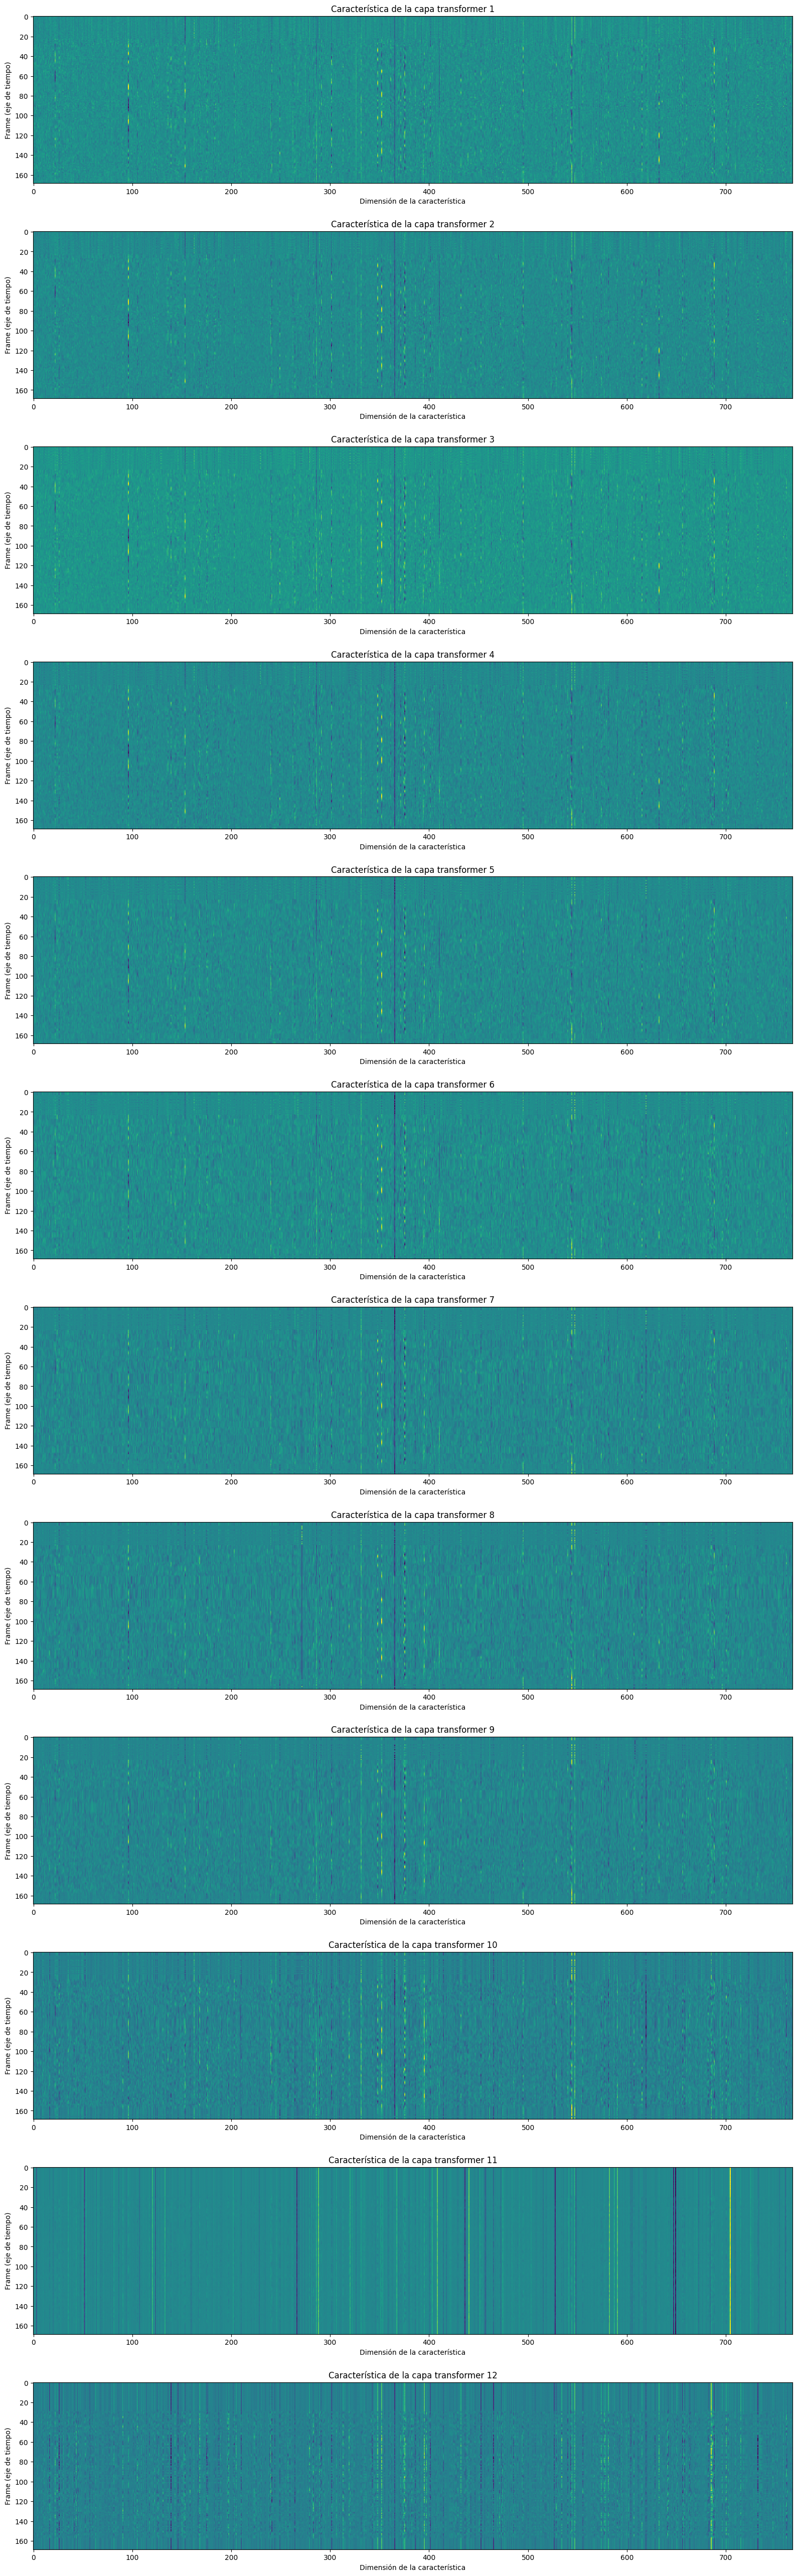

In [ ]:
fig, ax = plt.subplots(len(features), 1, figsize=(16, 4.3 * len(features)))
for i, feats in enumerate(features):
    ax[i].imshow(feats[0].cpu(), interpolation="nearest")
    ax[i].set_title(f"Característica de la capa transformer {i+1}")
    ax[i].set_xlabel("Dimensión de la característica")
    ax[i].set_ylabel("Frame (eje de tiempo)")
fig.tight_layout()
#en las primeras capas (1, 2 y 3) la representación visual es ruidosa y similar a la estática,
# ya que la red recién está captando frecuencias crudas y ruido de fondo

#al observar la capa 11, la matriz matemática se estructura en franjas verticales sólidas y muy definidas.
#Esto demuestra cómo el modelo purifica el sonido a medida que avanza,
#agrupando la acústica en bloques lógicos


#Clasificación de características

una vez que se extraidas las caracteristicas acusticas , el siguiente paso es clasificarlas en un conjunto de categorias (letras/etiquetas)

el Modelo Wav2Vec2 proporciona un metodo oara realizar la extraccion de caracteristicas y la clasificacion en un solo paso


In [24]:
#emission Es un tensor que, por cada minúscula fracción de segundo de tu audio, contiene 29 números
#Cada número representa qué tan segura está la red de haber escuchado una de las 29 opciones del diccionario

#esos nunmeros que son la probabilidad de que sea una determinada letra es lo que usa
#el algoritmo CTC , este se queda con el numero mas alto en cad ffraccion de segundo,
#limpia las letras repetidas y devuelve la traduccion final
with torch.inference_mode():
    emission, _ = model(waveform) #sale e n formato logits

Visualizando la salida

esta salida esta en formato "logits" (valores crudos sin normalizar) y no en un formato de probabilidad.

a continuacion lo vamos a visualizar

Etiquetas de clase: ('-', '|', 'E', 'T', 'A', 'O', 'N', 'I', 'H', 'S', 'R', 'D', 'L', 'U', 'M', 'W', 'C', 'F', 'G', 'Y', 'P', 'B', 'V', 'K', "'", 'X', 'J', 'Q', 'Z')


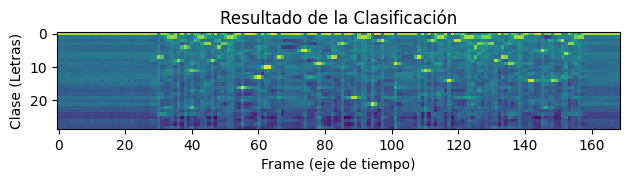

In [ ]:
plt.imshow(emission[0].cpu().T, interpolation="nearest")
plt.title("Resultado de la Clasificación")
plt.xlabel("Frame (eje de tiempo)")
plt.ylabel("Clase (Letras)")
plt.tight_layout()
print("Etiquetas de clase:", bundle.get_labels())
#'-' representa el silencio en el audio
# | representa los espacios entre palabras

#Los puntos amarillos: Representan el pico de probabilidad estadística.
# Donde ves un píxel amarillo brillante,
#la red está confirmando con alta seguridad que detectó esa letra específica en ese frame exacto.

# Generando transcripciones /"DECODIFICACION"


A partir de la secuencia de probabilidades de etiquetas, ahora queremos generar
la transcripción (el texto final). El proceso para generar esta hipótesis
se suele llamar "decodificación".
La decodificación es más elaborada que una simple clasificación porque
la decisión en un momento determinado puede verse afectada por las
observaciones del entorno (contexto).
Hay muchas técnicas de decodificación propuestas, y suelen requerir recursos
externos como diccionarios de palabras y modelos de lenguaje.
En este tutorial, para mantenerlo simple, realizaremos una "decodificación golosa"
(greedy decoding) que no depende de componentes externos, y simplemente elige
la mejor hipótesis en cada paso de tiempo. Por lo tanto, no usa información de contexto,
y solo genera una transcripción posible.
Empezamos definiendo el algoritmo de Greedy Decoding.


In [22]:
#esta clase lo que hace es convertir la matriz matematica que devuelve emission en texto
class GreedyCTCDecoder(torch.nn.Module):
    def __init__(self, labels, blank=0):
        super().__init__()
        self.labels = labels
        self.blank = blank

    def forward(self, emission: torch.Tensor) -> str:
        """Dada una secuencia de emisiones sobre etiquetas, obtiene la mejor cadena de texto.
        Argumentos:
          emission (Tensor): Tensores de logits. Forma `[num_seq, num_label]`.

        Retorna:
          str: La transcripción resultante.
        """
        indices = torch.argmax(emission, dim=-1)  #busca en emission el numero mas alto
        indices = torch.unique_consecutive(indices, dim=-1) #elimina letras repetidas
        indices = [i for i in indices if i != self.blank] # borra los indices que representan el silencio puro 0
        return "".join([self.labels[i] for i in indices]) #toma los indices numericos que superaron el filtrado y los une en una cadena de texto

Creando el objeto decodificador y decodificamos la transcripcion

In [25]:
#intancio la clase GreedyCTCDecoder
decoder = GreedyCTCDecoder(labels=bundle.get_labels())
#l
transcript = decoder(emission[0])

Revisamos el resultado y escuchamos nuevamente el audio

In [ ]:
#y aca vemos el audio original y las letras que adivino la red
print(transcript)
IPython.display.Audio(SPEECH_FILE)

I|HAD|THAT|CURIOSITY|BESIDE|ME|AT|THIS|MOMENT|
